# Bi 2021 — Kidney RCC · 04 expression (EMT-TFs)
Unconditional final step. Score a widened EMT-TF panel (Snail/Zeb/Twist **plus** FOXC and PRRX, the Kürten lesson) gated on detectable expression, and read its direction along the developmental axis.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 7822 | pseudotime range 0.0 -> 10.43


### Detection-gated EMT-TF panel
Each candidate: expressing fraction, early/late means across the pseudotime terciles, and Spearman vs pseudotime. Factors below a 3% detection floor are not overlaid blind.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print('panel present:', present)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nfactors above the 3% detection floor: {ok.TF.tolist()}')
print(f'derived endpoints: {early_tf} (most root-shifted) <-> {late_tf} (most terminus-shifted)')

panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.194       0.199      0.122    -0.199    EARLY(root)
 FOXC1      0.019       0.026      0.003    -0.138    EARLY(root)
  ZEB1      0.030       0.030      0.014    -0.100    EARLY(root)
 SNAI2      0.018       0.015      0.007    -0.059    EARLY(root)
 SNAI1      0.004       0.003      0.001    -0.038    EARLY(root)
TWIST2      0.000       0.000      0.000    -0.029 LATE(terminus)
 PRRX1      0.000       0.000      0.000    -0.008 LATE(terminus)
 FOXC2      0.005       0.004      0.006    -0.003 LATE(terminus)

factors above the 3% detection floor: ['ZEB2']
derived endpoints: ZEB2 (most root-shifted) <-> ZEB2 (most terminus-shifted)


### Is the EMT axis bipolar (distinct root and terminus factors) or monotone?

In [5]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
ve = _vec(early_tf); pe = ve[ve>0]
thr_e = np.quantile(pe,0.75) if pe.size else np.inf
sel_e = ve > thr_e; early_pt = tn[sel_e].mean() if sel_e.any() else np.nan
vl = _vec(late_tf); pl_ = vl[vl>0]
thr_l = np.quantile(pl_,0.75) if pl_.size else np.inf
sel_l = vl > thr_l; sep = abs(tn[sel_l].mean() - early_pt)
bipolar = (df.set_index('TF').loc[early_tf,'frac_expr'] > 0.03) and (early_pt < 0.5) and (sep >= 0.15)
print(f'{early_tf} upper-quartile expressers mean pseudotime = {early_pt:.2f}; '
      f'endpoint separation = {sep:.2f} -> axis is {"BIPOLAR" if bipolar else "MONOTONE"}')
if not bipolar:
    strong = df[df.frac_expr>0.03].iloc[(df[df.frac_expr>0.03].rho_vs_t.abs().values).argmax()]
    dirn = 'root/mesenchymal-origin' if strong.rho_vs_t < 0 else 'terminus'
    print(f'No bipolar EMT-TF split: only {ok.TF.tolist()} clear the detection floor and all '
          f'canonical factors decline toward the Crest terminus. Strongest detectable factor = '
          f'{strong.TF} ({strong.frac_expr*100:.0f}% expressing, rho_vs_t={strong.rho_vs_t:+.2f}, '
          f'{dirn}-enriched).')

ZEB2 upper-quartile expressers mean pseudotime = 0.59; endpoint separation = 0.00 -> axis is MONOTONE
No bipolar EMT-TF split: only ['ZEB2'] clear the detection floor and all canonical factors decline toward the Crest terminus. Strongest detectable factor = ZEB2 (19% expressing, rho_vs_t=-0.20, root/mesenchymal-origin-enriched).


### Deliverable — `expression.pdf`
Monotone axis → graded map of the single strongest detectable EMT-TF, labelled by its actual direction (here ZEB2 marks the mesenchymal/gastrulation origin, not the terminus).

saved expression.pdf


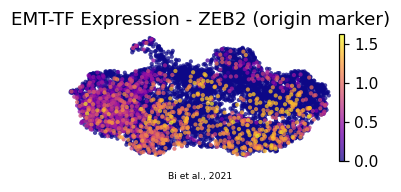

In [6]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
if bipolar:
    thr = {g: float(np.quantile(_vec(g)[_vec(g)>0],0.75)) for g in [early_tf, late_tf]}
    sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
    order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
    colors = {early_tf:'tab:blue', late_tf:'tab:red'}
    sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
    for g in order:
        sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=30, alpha=.8,
                   frameon=False, show=False, ax=ax)
    ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
else:
    strong = df[df.frac_expr>0.03].iloc[(df[df.frac_expr>0.03].rho_vs_t.abs().values).argmax()]
    g = strong.TF; dirn = 'origin' if strong.rho_vs_t < 0 else 'terminus'
    sc.pl.umap(adata, color=g, cmap='plasma', size=30, alpha=.75, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=f'EMT-TF Expression - {g} ({dirn} marker)')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14,'Bi et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf')